In [1]:
import os
import glob
import tifffile
import numpy as np
import matplotlib.pyplot as plt


In [5]:
folder_path = r"/home/students/rawat/training_data/data/train/images"
supported_extensions = ('.tif', '.tiff', '.png', '.jpg', '.jpeg')

# List all files in folder
files = [f for f in os.listdir(folder_path) if f.lower().endswith(supported_extensions)]

if not files:
    print("⚠️ No supported image files found in the folder.")

# Flags for post-check reporting
non_float32_found = False
out_of_range_found = False

# Print table header
print(f"{'File Name':40} {'Dtype':10} {'Min':10} {'Max':10} {'Status'}")
print("-"*80)

for fname in files:
    file_path = os.path.join(folder_path, fname)
    try:
        # Load image
        if fname.lower().endswith(('.tif', '.tiff')):
            img = tifffile.imread(file_path)
        else:
            img = np.array(Image.open(file_path))
        
        # Check dtype and min/max
        min_val = np.min(img)
        max_val = np.max(img)
        status = "✅ OK"

        if img.dtype == np.float32:
            dtype_str = "float32"
            # Check if values are within [0,1]
            if min_val < 0.0 or max_val > 1.0:
                out_of_range_found = True
                status = "⚠️ Out of range"
        else:
            non_float32_found = True
            dtype_str = str(img.dtype)
            status = "❌ Not float32"
        
        print(f"{fname:40} {dtype_str:10} {min_val:<10.4f} {max_val:<10.4f} {status}")
    
    except Exception as e:
        print(f"{fname:40} {'Error':10} {'-':10} {'-':10} ⚠️ {e}")

# Post-check summary
print("\nSummary of issues:")
if non_float32_found:
    print("❌ Some images are not float32.")
else:
    print("✅ All images are float32.")

if out_of_range_found:
    print("⚠️ Some float32 images have values outside [0,1].")
else:
    print("✅ All float32 images are in the range [0,1].")

File Name                                Dtype      Min        Max        Status
--------------------------------------------------------------------------------
Brain2_PN_KC_Group3_25minfix_OvernightSecAB_488_561_Calyx1_Confocal_slice_0030.tif float32    0.0000     1.0000     ✅ OK
PN_KC_Calyx_CS+_GFP_mCherry568_anti-synapsin633_slice_0038.tif float32    0.0000     1.0000     ✅ OK
PN_KC_Calyx_CS-_GFP_mCherry568_anti-synapsin633_brain1_slice_0029.tif float32    0.0000     1.0000     ✅ OK
PN_KC_488_568_633_30mins_Calyx2_deconvolved(FI)_slice_0043.tif float32    0.0000     1.0000     ✅ OK
PN_KC_Calyx_CS-_GFP_mCherry568_anti-synapsin633_brain1_slice_0084.tif float32    0.0000     1.0000     ✅ OK
PN_KC_Calyx_CS-_GFP_mCherry568_anti-synapsin633_brain1_slice_0055.tif float32    0.0000     1.0000     ✅ OK
Control_group_Brain1_PN_KC_anti_GFP_488_anti_RFP_568_LSMPlus_16bit_06.10.2025_slice_0040.tif float32    0.0000     1.0000     ✅ OK
PN_KC_488_568_633_30mins_Calyx2_deconvolved(FI)_slice_0044.t

In [17]:
INPUT_PATH = r"/home/students/rawat/czi_output/Annotations/Processed_labels/PN_KC_488_568_Brain1_CalyxL_LSMPlus_16bit.ims - PN_KC_488_568_Brain1_CalyxL_LSMPlus_16bit_Surface_Mask_Boutons.tif"
img = tifffile.imread(INPUT_PATH)
print(f"Image shape: {img.shape}, dtype: {img.dtype}")

print(f"1. Shape: {img.shape}")
print(f"2. Data Type: {img.dtype}")
print(f"3. Min Value: {img.min()}")
print(f"4. Max Value: {img.max()}")
print(f"5. Mean Value: {img.mean()}")

# Check if it's mostly empty
non_zero_count = np.count_nonzero(img)
total_pixels = img.size
print(f"6. Non-zero pixels: {non_zero_count} ({non_zero_count/total_pixels:.4%})")

Image shape: (75, 2, 1101, 1101), dtype: uint16
1. Shape: (75, 2, 1101, 1101)
2. Data Type: uint16
3. Min Value: 0
4. Max Value: 63518
5. Mean Value: 96.37897383904705
6. Non-zero pixels: 91036120 (50.0666%)


In [12]:
if img.ndim == 4:
    if img.shape[0] <= 4:  # (C, Z, Y, X)
        img = np.transpose(img, (1, 2, 3, 0))
    elif img.shape[1] <= 4:  # (Z, C, Y, X)
        img = np.transpose(img, (0, 2, 3, 1))
elif img.ndim == 3:
        # Assume (Z, Y, X) if 3D, add dummy channel dim -> (Z, Y, X, 1)
        img = img[..., np.newaxis]

print(f"Processed shape (Z, Y, X): {img.shape}")

## Check if data is not uint8, then normalize to 0-255
if img.dtype != np.uint8:
        print(f"The data type is {img.dtype}, normalizing to uint8.")
        # Calculate percentiles on the entire 3D volume at once
        low, high = np.percentile(img, (1, 99))
        if high > low:
            img = (img.astype(float) - low) / (high - low)
            img = np.clip(img, 0, 1) * 255
        else:
            img = np.zeros(img.shape)

Z, Y, X, C = img.shape
raw_data_rgb = np.zeros((Z, Y, X, 3), dtype=img.dtype)

raw_data_rgb[..., :min(C, 2)] = img[..., :min(C, 2)]
print("\n--- STATISTICS ---")
print(f"Shape: {img.shape}")
print(f"Data Type (dtype): {img.dtype}")
print(f"Minimum Value: {img.min()}")
print(f"Maximum Value: {img.max()}")
print(f"Mean Value:    {img.mean():.2f}")


## Print statistics for Rgb image
print("\n--- RGB STATISTICS ---")
print(f"Shape: {raw_data_rgb.shape}")
print(f"Data Type (dtype): {raw_data_rgb.dtype}")
print(f"Minimum Value: {raw_data_rgb.min()}")
print(f"Maximum Value: {raw_data_rgb.max()}")
print(f"Mean Value:    {raw_data_rgb.mean():.2f}")

Processed shape (Z, Y, X): (75, 1101, 1101, 2)
The data type is uint16, normalizing to uint8.

--- STATISTICS ---
Shape: (75, 1101, 1101, 2)
Data Type (dtype): float64
Minimum Value: 0.0
Maximum Value: 255.0
Mean Value:    17.44

--- RGB STATISTICS ---
Shape: (75, 1101, 1101, 3)
Data Type (dtype): float64
Minimum Value: 0.0
Maximum Value: 255.0
Mean Value:    11.63


In [13]:
img_slice = raw_data_rgb[51]

print(f"\n2D Slice shape: {img_slice.shape}, dtype: {img_slice.dtype}")


2D Slice shape: (1101, 1101, 3), dtype: float64


In [4]:
LABEL_PATH = r"/home/students/rawat/training_data/data/train/labels/Brain2_PN_KC_Group3_25minfix_OvernightSecAB_488_561_Calyx1_Confocal_slice_0015.tif"

label = tifffile.imread(LABEL_PATH)

print(label.shape)

(1101, 1101)


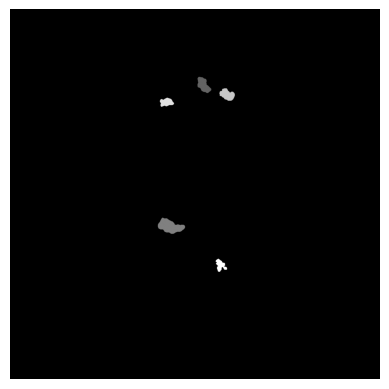

In [5]:
plt.imshow(label, cmap='gray')
plt.axis('off')
plt.show()